# 02 · How good is the production model?

**Goal:** check the model the API serves on the validation days (22-31 January 2025), beyond its single RMSE: where it is strong, where it is weak, and whether it holds up over time.

The figures come from `src/trip_duration/evaluate.py`, the same code as `uv run trip-duration evaluate`. This notebook needs the MLflow server with a promoted model (`docker compose up -d --wait mlflow`).

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from trip_duration import config, data, evaluate, features

pd.set_option("display.float_format", "{:,.3f}".format)
IMAGES = config.PROJECT_ROOT / "docs" / "images"
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
    }
)

In [2]:
model, version = evaluate.load_production()
trips = data.load_trips()
report = evaluate.evaluate(model, trips)
by_length = report.pop("by_trip_length")
print(f"Production model: trip-duration version {version}")
pd.Series(report).to_frame("value")

Production model: trip-duration version 2


,value
validation_trips,"1,167,015.000"
rmse,4.619
mae,3.155
median_abs_error,2.275
r2,0.771
bias,-0.554
share_within_1_min,0.236
share_within_2_min,0.448
share_within_3_min,0.619
share_within_5_min,0.823


## Headline

- **RMSE 4.62 min, median miss 2.3 min, R² 0.77**, using only what is known at booking: zones and pickup time.
- **82% of trips within ±5 minutes.**
- **Training RMSE 4.29 against validation 4.62:** a small gap, so little overfitting.
- **Daily RMSE stays between 4.15 and 4.79 minutes**, so the error is stable over the ten days.

## Where it is weak: long trips

In [3]:
by_length

,trips,share,mae,bias
band,,,,
"(0.999, 5.0]",119912,0.103,2.778,2.761
"(5.0, 10.0]",341733,0.293,1.948,1.023
"(10.0, 20.0]",463806,0.397,2.777,-0.671
"(20.0, 30.0]",158645,0.136,4.424,-2.700
"(30.0, 45.0]",62429,0.053,7.124,-5.532
"(45.0, 60.0]",20490,0.018,12.143,-11.826


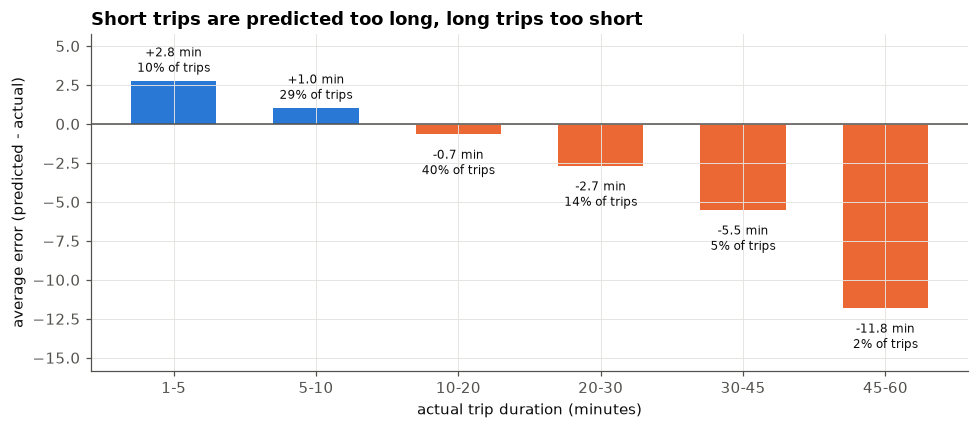

In [4]:
labels = ["1-5", "5-10", "10-20", "20-30", "30-45", "45-60"]
fig, ax = plt.subplots()
colors = [ORANGE if b < 0 else BLUE for b in by_length["bias"]]
ax.bar(labels, by_length["bias"], color=colors, width=0.6)
ax.axhline(0, color=MUTED, linewidth=1)
for i, (bias, share) in enumerate(
    zip(by_length["bias"], by_length["share"], strict=True)
):
    ax.annotate(
        f"{bias:+.1f} min\n{share:.0%} of trips",
        (i, bias),
        xytext=(0, 6 if bias >= 0 else -26),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=INK,
    )
ax.set(
    title="Short trips are predicted too long, long trips too short",
    xlabel="actual trip duration (minutes)",
    ylabel="average error (predicted - actual)",
)
ax.set_ylim(by_length["bias"].min() - 4, by_length["bias"].max() + 3)
fig.tight_layout()
fig.savefig(IMAGES / "error_by_trip_length.png")

The model pulls extreme trips towards the middle, as averaging models do. Very short trips come out almost 3 minutes too long, and trips of 45-60 minutes (2% of trips) about 12 minutes too short. For trips of 5-20 minutes, 69% of all trips, the average error stays within about a minute either way.

## Airport trips and the late-January slowdown

In [5]:
print(f"Trips to or from JFK/LaGuardia: {report['airport_share']:.1%}")
print(
    f"  MAE airport trips: {report['airport_mae']:.2f} min, other trips: {report['other_mae']:.2f} min"
)
slower = 1 - report["median_mph_validation"] / report["median_mph_train"]
print(
    f"Median speed: training days {report['median_mph_train']:.2f} mph, validation days {report['median_mph_validation']:.2f} mph ({slower:.0%} slower)"
)
print(f"Overall bias: {report['bias']:+.2f} min (negative = predictions too short)")

Trips to or from JFK/LaGuardia: 6.7%
  MAE airport trips: 4.76 min, other trips: 3.04 min
Median speed: training days 9.85 mph, validation days 9.27 mph (6% slower)
Overall bias: -0.55 min (negative = predictions too short)


Airport trips are long, and their duration depends on traffic the features can't see, so they miss by about half as much again as other trips. The validation days were about 6% slower than the training days, and the model predicts about half a minute too short on average. A random split would have hidden that drift; the date split shows it.

## Speed of one prediction

In [6]:
one_trip = features.build_features(trips.head(1))
model.predict(one_trip)  # warm up
runs = 50
start = time.perf_counter()
for _ in range(runs):
    model.predict(one_trip)
print(f"One prediction: {(time.perf_counter() - start) / runs * 1000:.0f} ms")

One prediction: 17 ms


Fast enough for an API answering one booking at a time. The number depends on the machine.